# 02 · Retenção, logística e frete/pagamento (perguntas 4 a 6)

**Pré-requisito:** `python -m src.run_clean && python -m src.run_model`.

**Atenção:** clientes são contados por `customer_unique_id` (o `customer_id` muda a cada pedido).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import viz
from src.viz import AZUL, CINZA, VERMELHO

viz.setup()
m = viz.load_model()
fo, fi, dc, dp, ds = m["fact_orders"], m["fact_items"], m["dim_customer"], m["dim_product"], m["dim_seller"]

## Pergunta 4 · Clientes recorrentes vs. compra única (cohort)

In [2]:
# Pedidos válidos; cada pessoa é identificada por customer_unique_id
v = fo[fo["is_valid_order"]]
pedidos_por_pessoa = v.groupby("customer_unique_id")["order_id"].count()
rec = pedidos_por_pessoa > 1
print(f"Clientes: {len(rec):,} | Recorrentes: {rec.sum():,} ({rec.mean():.2%})")
print("Distribuição de nº de pedidos:", pedidos_por_pessoa.value_counts().sort_index().head(5).to_dict())
receita = v.groupby("is_recurring_customer")["revenue"].sum()
print(f"Receita vinda de recorrentes: {receita[True]/receita.sum():.1%}")

# Tempo entre 1ª e 2ª compra (somente quem voltou)
seq = v.set_index("customer_unique_id")
t1 = seq[seq.customer_order_seq == 1]["order_purchase_timestamp"]
t2 = seq[seq.customer_order_seq == 2]["order_purchase_timestamp"]
dias = (t2 - t1.reindex(t2.index)).dt.days
print(f"Dias até a 2ª compra: mediana {dias.median():.0f} | voltam em até 30 dias: {(dias <= 30).mean():.0%}")

Clientes: 94,990 | Recorrentes: 2,888 (3.04%)
Distribuição de nº de pedidos: {1: 92102, 2: 2652, 3: 188, 4: 29, 5: 9}
Receita vinda de recorrentes: 5.6%
Dias até a 2ª compra: mediana 28 | voltam em até 30 dias: 51%


Retenção média: M+1: 0.48% | M+3: 0.26% | M+6: 0.26%


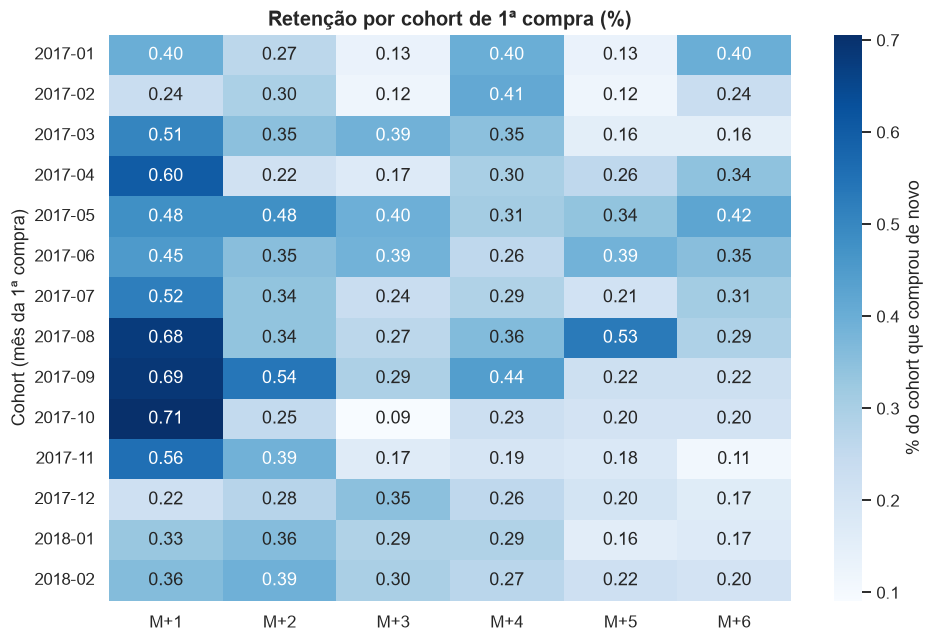

In [3]:
# Cohort: % dos clientes de cada mês de 1ª compra que voltam a comprar k meses depois
c = v.assign(cohort=v["cohort_month"].dt.to_period("M"), mes=v["purchase_date"].dt.to_period("M"))
c = c[c["cohort"].between("2017-01", "2018-02")]   # cohorts com ao menos 6 meses observáveis (janela vai até ago/2018)
c = c[c["mes"] <= "2018-08"]
ativos = c.groupby(["cohort", "mes"])["customer_unique_id"].nunique().unstack()
tamanho = c[c.customer_order_seq == 1].groupby("cohort")["customer_unique_id"].nunique()

ret = pd.DataFrame({f"M+{k}": [ativos.loc[co].get(co + k, np.nan) / tamanho[co] for co in ativos.index]
                    for k in range(1, 7)}, index=[str(i) for i in ativos.index])
print("Retenção média: " + " | ".join(f"{k}: {ret[k].mean():.2%}" for k in ["M+1", "M+3", "M+6"]))

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ret * 100, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "% do cohort que comprou de novo"}, ax=ax)
ax.set_title("Retenção por cohort de 1ª compra (%)"); ax.set_ylabel("Cohort (mês da 1ª compra)")
plt.tight_layout(); viz.savefig("q4_cohort_retencao"); plt.show()

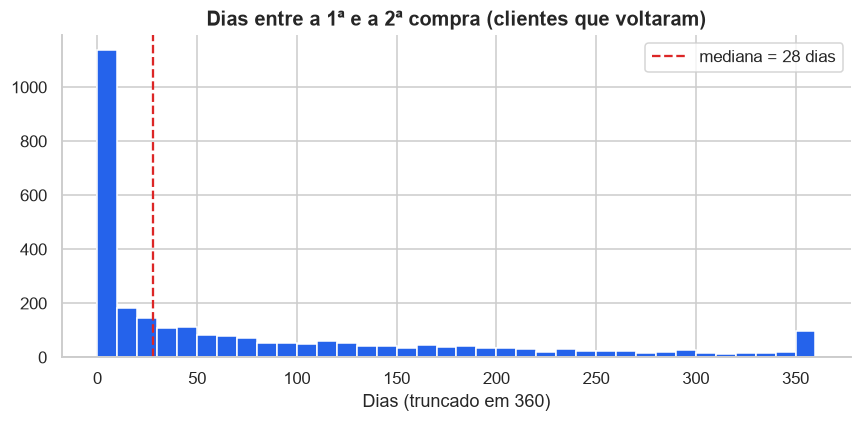

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dias.clip(upper=360), bins=36, color=AZUL)
ax.axvline(dias.median(), color=VERMELHO, ls="--", label=f"mediana = {dias.median():.0f} dias")
ax.set_title("Dias entre a 1ª e a 2ª compra (clientes que voltaram)"); ax.set_xlabel("Dias (truncado em 360)"); ax.legend()
plt.tight_layout(); viz.savefig("q4_tempo_segunda_compra"); plt.show()

### 💡 Insight
- Apenas **3,0% dos clientes (2.888 de 94.990) compraram mais de uma vez**, e eles geram só **5,6% da receita**. O negócio vive de **aquisição**, não de fidelização.
- A retenção por cohort é minúscula: em média **0,48% voltam no mês seguinte** e cerca de **0,26% no 3º e no 6º mês**, sem diferença relevante entre os cohorts.
- Entre os que voltam, a **mediana é 28 dias e 51% voltam em até 30 dias**. Quem recompra, recompra cedo.

**Recomendação:** concentrar a ação de recompra nos **30 primeiros dias** (e-mail/cupom pós-entrega, cross-sell de categoria complementar). Cada ponto percentual de recompra adicional equivale a cerca de 950 clientes e mais receita sem custo de aquisição. Antes de investir, confirmar se o `customer_unique_id` é um bom identificador, porque cadastros duplicados subestimariam a recompra.

## Pergunta 5 · Vendedores e categorias com pior desempenho logístico

In [5]:
# Pedidos entregues com data. is_late = entregue depois da data estimada
e = fo[fo["is_late"].notna()].merge(dc[["customer_id", "customer_state"]], on="customer_id")
print(f"Taxa de atraso global: {e['is_late'].mean():.1%} | prazo mediano: {e['delivery_days'].median():.1f} dias")

# --- Vendedores (mínimo de 30 pedidos para a taxa ser estável) ---
li = fi[fi["is_late"].notna()].copy()
li["late"] = li["is_late"].astype(bool)
vend = li.groupby("seller_id").agg(pedidos=("order_id", "nunique"), taxa_atraso=("late", "mean"), receita=("revenue", "sum"))
grandes = vend[vend.pedidos >= 30]
ruins = grandes[grandes.taxa_atraso > 0.15]
print(f"\nVendedores com >= 30 pedidos: {len(grandes)} | com mais de 15% de atraso: {len(ruins)}")
print(f"Eles respondem por {ruins.pedidos.sum()/vend.pedidos.sum():.1%} dos pedidos e {ruins.receita.sum()/vend.receita.sum():.1%} da receita")
grandes.sort_values("taxa_atraso", ascending=False).head(5).round(3)

Taxa de atraso global: 6.8% | prazo mediano: 10.2 dias

Vendedores com >= 30 pedidos: 627 | com mais de 15% de atraso: 40
Eles respondem por 3.3% dos pedidos e 2.8% da receita


,pedidos,taxa_atraso,receita
seller_id,,,
54965bbe3e4f07ae045b90b0b8541f52,73,0.321,10351.70
ede0c03645598cdfc63ca8237acbe73d,43,0.319,2352.15
ad781527c93d00d89a11eecd9dcad7c1,38,0.316,6039.63
2a1348e9addc1af5aaa619b1a3679d6b,48,0.294,2697.40
835f0f7810c76831d6c7d24c7a646d4d,42,0.271,4990.20


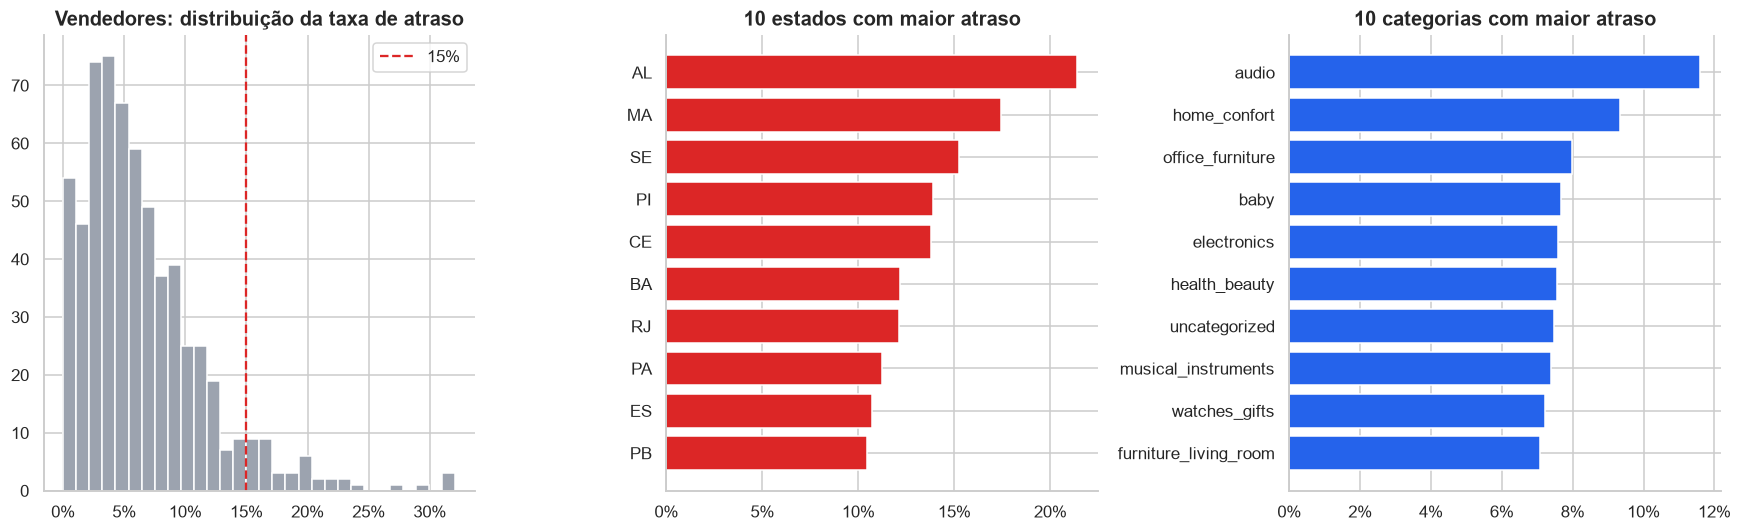

                pedidos  taxa_atraso  prazo_mediano
customer_state                                     
AL                  397        0.214          22.33
MA                  717        0.174          19.19
SE                  335        0.152          18.01
                pedidos  taxa_atraso  prazo_mediano
customer_state                                     
MG                11354        0.046          10.31
SP                40494        0.045           7.21
PR                 4923         0.04          10.43


In [6]:
# --- Estados (>= 300 pedidos) ---
est = e.groupby("customer_state").agg(pedidos=("order_id", "count"), taxa_atraso=("is_late", "mean"), prazo_mediano=("delivery_days", "median"))
est = est[est.pedidos >= 300].sort_values("taxa_atraso", ascending=False)

# --- Categorias (>= 300 pedidos) ---
li = li.merge(dp[["product_id", "category_en"]], on="product_id")
cat = li.groupby("category_en").agg(pedidos=("order_id", "nunique"), taxa_atraso=("late", "mean"))
cat = cat[cat.pedidos >= 300].sort_values("taxa_atraso", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].hist(grandes["taxa_atraso"], bins=30, color=CINZA)
axes[0].axvline(0.15, color=VERMELHO, ls="--", label="15%")
axes[0].set_title("Vendedores: distribuição da taxa de atraso"); axes[0].legend(); viz.pct_fmt(axes[0], "x")
t = est.head(10)[::-1]; axes[1].barh(t.index, t["taxa_atraso"], color=VERMELHO); axes[1].set_title("10 estados com maior atraso")
t = cat.head(10)[::-1]; axes[2].barh(t.index, t["taxa_atraso"], color=AZUL); axes[2].set_title("10 categorias com maior atraso")
viz.pct_fmt(axes[1], "x"); viz.pct_fmt(axes[2], "x")
plt.tight_layout(); viz.savefig("q5_logistica"); plt.show()
print(est.head(3).round(3).to_string()); print(est.tail(3).round(3).to_string())

### 💡 Insight
- **Vendedores:** de 627 vendedores com volume relevante, **40 têm mais de 15% de atraso**, mas eles são só **3,3% dos pedidos e 2,8% da receita**. O problema existe, porém é pequeno e fácil de isolar.
- **Geografia pesa mais:** a taxa de atraso global é 6,8%, mas **AL chega a 21,4%** (prazo mediano de 22 dias), seguido de MA (17,4%), SE (15,2%), PI e CE (~14%). Em SP são **4,5%** e 7,2 dias de prazo mediano.
- **Categorias:** áudio (11,6%), home_confort (9,3%) e móveis de escritório (8,0%) lideram em atraso. Bagagem (4,2%) e eletrodomésticos (4,5%) são as melhores.

**Recomendação:** (1) notificar/penalizar os 40 vendedores problemáticos, o que é rápido e barato; (2) para o **Nordeste, o gargalo parece ser transportadora/distância**, não vendedor: negociar transportadora regional ou estoque avançado e ajustar a promessa de prazo (veja o insight da pergunta 3).

## Pergunta 6 · Como frete e forma de pagamento influenciam o valor dos pedidos?

Frete = 16.6% da receita (agregado) | mediana por pedido: 22.4%
Correlação valor do pedido x frete: 0.41


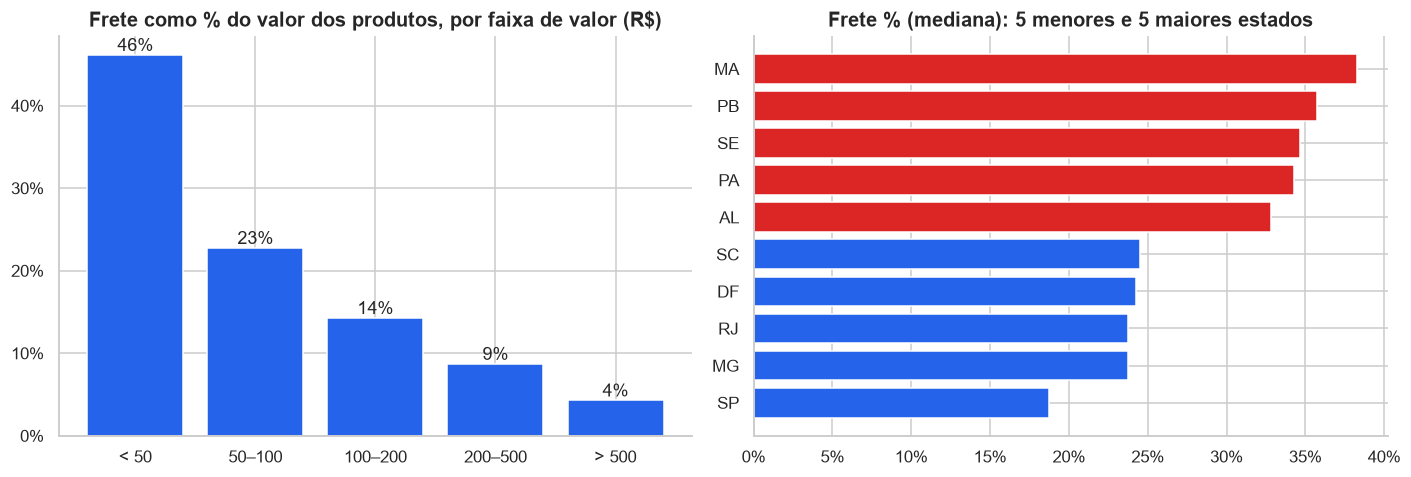

,pedidos,frete_pct
customer_state,,
SP,41021,0.187
MG,11457,0.237
MA,732,0.383
PB,530,0.357


In [7]:
# Pedidos válidos, com item, na janela de análise
w = (viz.no_periodo(fo[fo["is_valid_order"] & (fo["revenue"] > 0)])
     .merge(dc[["customer_id", "customer_state"]], on="customer_id"))
w["frete_pct"] = w["freight"] / w["revenue"]     # peso do frete em relação ao valor dos produtos

print(f"Frete = {w.freight.sum()/w.revenue.sum():.1%} da receita (agregado) | mediana por pedido: {w.frete_pct.median():.1%}")
print(f"Correlação valor do pedido x frete: {w[['revenue','freight']].corr().iloc[0,1]:.2f}")

w["faixa_valor"] = pd.cut(w["revenue"], [0, 50, 100, 200, 500, 1e9], labels=["< 50", "50–100", "100–200", "200–500", "> 500"])
por_valor = w.groupby("faixa_valor", observed=True)["frete_pct"].median()

est = w.groupby("customer_state").agg(pedidos=("order_id", "count"), frete_pct=("frete_pct", "median"))
est = est[est.pedidos >= 300].sort_values("frete_pct")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(por_valor.index.astype(str), por_valor.values, color=AZUL)
for i, v in enumerate(por_valor.values):
    axes[0].text(i, v, f"{v:.0%}", ha="center", va="bottom")
axes[0].set_title("Frete como % do valor dos produtos, por faixa de valor (R$)"); viz.pct_fmt(axes[0])
sel = pd.concat([est.head(5), est.tail(5)])
axes[1].barh(sel.index, sel["frete_pct"], color=[AZUL] * 5 + [VERMELHO] * 5)
axes[1].set_title("Frete % (mediana): 5 menores e 5 maiores estados"); viz.pct_fmt(axes[1], "x")
plt.tight_layout(); viz.savefig("q6_frete"); plt.show()
est.loc[[u for u in ["SP", "MG", "MA", "PB"] if u in est.index]].round(3)

Pedidos no cartão de crédito: 75.5% | pedidos parcelados: 51.5%


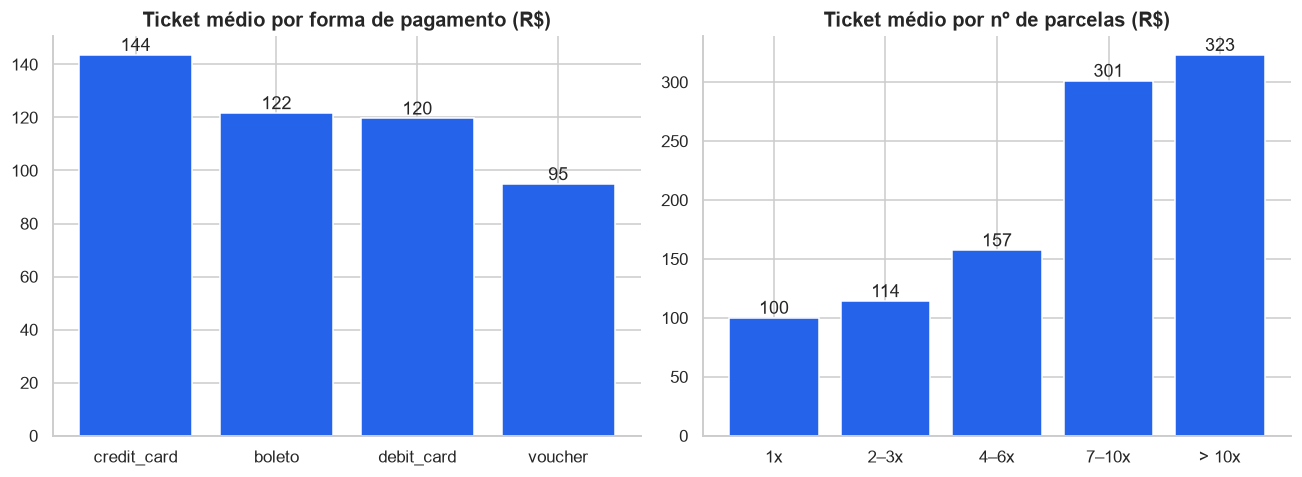

,pedidos,ticket_medio,ticket_mediano
payment_type_main,,,
boleto,19477,121.7,75.0
credit_card,73888,143.6,89.9
debit_card,1512,119.6,70.0
voucher,3028,94.9,60.0


,pedidos,ticket_medio
parcelas,,
1x,47492,100.2
2–3x,22485,114.3
4–6x,15966,157.4
7–10x,11624,301.2
> 10x,336,323.1


q
Q1 (menor)    4.16
Q2            4.13
Q3            4.11
Q4 (maior)    4.08
Name: review_score, dtype: float64

In [8]:
# --- Forma de pagamento (a de maior valor no pedido) e parcelamento ---
pg = w.groupby("payment_type_main").agg(pedidos=("order_id", "count"), ticket_medio=("revenue", "mean"), ticket_mediano=("revenue", "median"))
w["parcelas"] = pd.cut(w["installments_max"], [0, 1, 3, 6, 10, 100], labels=["1x", "2–3x", "4–6x", "7–10x", "> 10x"])
parc = w.groupby("parcelas", observed=True).agg(pedidos=("order_id", "count"), ticket_medio=("revenue", "mean"))
print(f"Pedidos no cartão de crédito: {(w.payment_type_main=='credit_card').mean():.1%} | pedidos parcelados: {(w.installments_max>1).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
p = pg[pg.pedidos > 1000].sort_values("ticket_medio", ascending=False)
axes[0].bar(p.index, p["ticket_medio"], color=AZUL); axes[0].set_title("Ticket médio por forma de pagamento (R$)")
for i, v in enumerate(p["ticket_medio"]):
    axes[0].text(i, v, f"{v:.0f}", ha="center", va="bottom")
axes[1].bar(parc.index.astype(str), parc["ticket_medio"], color=AZUL); axes[1].set_title("Ticket médio por nº de parcelas (R$)")
for i, v in enumerate(parc["ticket_medio"]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom")
plt.tight_layout(); viz.savefig("q6_pagamento"); plt.show()
display(pg.round(1)); display(parc.round(1))

# O frete alto prejudica a avaliação? (nota média por quartil de frete%)
nota = w[w["review_score"].notna()].assign(q=lambda d: pd.qcut(d["frete_pct"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]))
nota.groupby("q", observed=True)["review_score"].mean().round(2)

### 💡 Insight
- **O frete pesa mais em pedidos baratos:** pedidos abaixo de R$ 50 pagam frete equivalente a **46% do valor dos produtos** (mediana), contra **4% acima de R$ 500**. No agregado, o frete é 16,6% da receita.
- **Distância custa:** a mediana do frete é 18,7% do valor em SP e chega a **38% no MA e 36% na PB**.
- **Pagamento:** 75% dos pedidos são no cartão de crédito, que tem o maior ticket (R$ 144), contra boleto (R$ 122) e voucher (R$ 95). **51% dos pedidos são parcelados**, e o ticket cresce muito com as parcelas: **R$ 100 em 1x vs R$ 301 em 7–10x**. É correlação, não causa: compras caras tendem a ser parceladas, mas o parcelamento também é o que viabiliza o ticket alto.
- O frete alto pouco afeta a nota: de 4,16 (menor frete%) a 4,08 (maior).

**Recomendação:** (1) testar um **piso de frete grátis** voltado a pedidos pequenos, onde o frete tem peso desproporcional (um teste A/B mede o efeito, pois os dados não permitem concluir causalidade); (2) **manter e divulgar o parcelamento em até 10x**, que sustenta o ticket alto; (3) no Nordeste, frete alto soma-se a prazo longo, e esse é o gargalo de expansão.